This is a continuation of the work I did in `2026_07_21_imagery_and_weather_station_data_exploration`. Last time we verified that the NEU area is well covered by Google Street View. In this work session I'll focus on:

<ol>
<li>Collecting imagery for buildings in the area (today).</li>
<li>Computing quality indicators for the imagery (tomorrow.)</li>
</ol>

The idea would be to acquire those indicators that we used for building the framework in the `Imageable` paper. 

Text(0.5, 1.0, 'Street network')

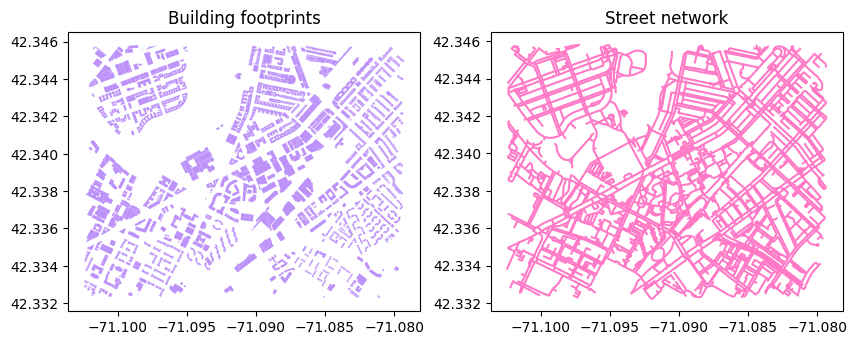

In [1]:

### To apply the Imageable library we need a GDF with the building footprints.
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

FOOTPRINTS_DATA_PATH = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_03_imagery_quality_assessment/boston_buildings_study_area.geojson")

STREET_NETWORK_DATA_PATH = "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/" \
"2026_08_03_imagery_quality_assessment/street_network.geojson"

gdf_footprints = gpd.read_file(FOOTPRINTS_DATA_PATH)
gdf_street_network = gpd.read_file(STREET_NETWORK_DATA_PATH)

fig, ax = plt.subplots(1, 2, figsize = (10, 5))
DRACULA_PURPLE = "#bd93f9"
DRACULA_PINK = "#ff79c6"
gdf_footprints.plot(ax = ax[0], color = DRACULA_PURPLE, edgecolor = "none", figsize = (5,5))
gdf_street_network.plot(ax = ax[1], color = DRACULA_PINK, edgecolor = "none", figsize = (5,5))
ax[0].set_title("Building footprints")
ax[1].set_title("Street network")

In [2]:
from imageable.core.image import get_image
from tqdm import tqdm

API_KEY = ""

PARENT_IMAGES = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_03_imagery_quality_assessment/images")

def download_image(polygon, index, key = API_KEY, prefix = "building_"):
    save_path = PARENT_IMAGES/Path(prefix+str(index))
    _, _, metadata = get_image(
        key = key,
        footprint = polygon,
        street_network = gdf_street_network,
        overwrite = False,
        save_path = save_path
    )

    return metadata

n_polygons = len(gdf_footprints)
print(f"There are {n_polygons} polygons")
geometries = list(gdf_footprints["geometry"])


/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


There are 2456 polygons


In [3]:
for i in tqdm(range(0,n_polygons)):
    polygon = geometries[i]
    index = i
    try:
        metadata = download_image(
            polygon = polygon,
            index = index
        )
        print(metadata)
    except Exception:
        continue

  0%|          | 0/2456 [00:00<?, ?it/s]

{'status': True, 'date': '2022-09', 'img_size': [640, 640], 'source': '© Google', 'latitude': 42.34476908989261, 'longitude': -71.09813932110826, 'pano_id': 'LGjjqeYaWeuNmk1P8v4hhQ', 'camera_parameters': {'longitude': -71.09816721309103, 'latitude': 42.34480588732934, 'fov': 90, 'heading': 244.18840296229354, 'pitch': 0, 'width': 640, 'height': 640}, 'adjustment_success': True}
{'status': True, 'date': '2024-08', 'img_size': [640, 640], 'source': '© Google', 'latitude': 42.34506009475644, 'longitude': -71.09955332146023, 'pano_id': 'ckYmbX5dmIdaF3vxJZQ7_A', 'camera_parameters': {'longitude': -71.09976013857643, 'latitude': 42.34540871743207, 'fov': 90, 'heading': 30.248667167124722, 'pitch': 18.0, 'width': 640, 'height': 640}, 'adjustment_success': True}
{'status': True, 'date': '2026-06', 'img_size': [640, 640], 'source': '© Google', 'latitude': 42.34457738716345, 'longitude': -71.089497717547, 'pano_id': 'tFso_nLs9v2fRbWteqYZWA', 'camera_parameters': {'longitude': -71.08944007634358,

  0%|          | 6/2456 [00:08<55:25,  1.36s/it]

{'refinement_iterations': 5, 'refinement_success': True, 'min_floor_ratio': 1e-05, 'min_sky_ratio': 0.1}


  0%|          | 7/2456 [00:15<1:44:35,  2.56s/it]

{'refinement_iterations': 5, 'refinement_success': False, 'min_floor_ratio': 1e-05, 'min_sky_ratio': 0.1}


... (68 outputs left out)

  2%|▏         | 42/2456 [03:42<3:10:28,  4.73s/it]

{'refinement_iterations': 5, 'refinement_success': True, 'min_floor_ratio': 1e-05, 'min_sky_ratio': 0.1}


  2%|▏         | 42/2456 [03:49<3:39:28,  5.46s/it]


KeyboardInterrupt: 

?get_dataset

In [5]:
?get_image

Signature:
get_image(
    key: 'str',
    footprint: 'Polygon',
    *,
    save_path: 'str | Path | None' = None,
    return_metadata: 'bool' = True,
    refine_camera: 'bool' = True,
    min_floor_ratio: 'float' = 1e-05,
    min_sky_ratio: 'float' = 0.1,
    max_refinement_iterations: 'int' = 5,
    overwrite: 'bool' = True,
    street_network: 'Any | None' = None,
) -> 'tuple[np.ndarray | None, CameraParameters] | tuple[np.ndarray | None, CameraParameters, dict[str, Any]] | np.ndarray | None'
Docstring:
Get street view image for a building footprint.

This function acquires a street view image of a building, optionally
refining camera parameters to ensure the full façade is visible.

Parameters
----------
key : str
    Google Street View API key.
footprint : shapely.Polygon
    Building footprint geometry.
save_path : str or Path, optional
    Directory to save the downloaded image and metadata.
return_metadata : bool, default=True
    Whether to return camera parameters and addition

In [19]:
metadata

{'refinement_iterations': 5,
 'refinement_success': True,
 'min_floor_ratio': 1e-05,
 'min_sky_ratio': 0.1}